#### Representational & Functional comparison    

In [ ]:
# --- set-up
import re
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import yaml
import torch
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

OG_PATH = "Data/ERA5_og/best_model_checkpoint.pt"
CORR_PATH = "Data/best_model_checkpoint.pt"
CONFIG_PATH = "Data/credit_model_config.yml"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

##### load config file and build the model architecture from it    

In [2]:
with open(CONFIG_PATH) as f:
    conf = yaml.safe_load(f)

model_conf = {k: v for k, v in conf["model"].items() if k != "type"}
print(f"model type: {conf['model']['type']}")
print(f"dim={model_conf['dim']}  depth={model_conf['depth']}")
print(f"image_height={model_conf['image_height']}  image_width={model_conf['image_width']}")
print(f"channels={model_conf['channels']}  levels={model_conf['levels']}  "
      f"surface_channels={model_conf['surface_channels']}  "
      f"input_only_channels={model_conf['input_only_channels']}  "
      f"output_only_channels={model_conf['output_only_channels']}")

model type: crossformer
dim=[64, 128, 256, 512]  depth=[2, 2, 4, 2]
image_height=721  image_width=1440
channels=5  levels=2  surface_channels=8  input_only_channels=4  output_only_channels=4


##### build variable name lists (double check the sequence)    

In [3]:
data_conf = conf["data"]
# level labels: the config comments say "variables at 500hPa, 850hPa" for levels=2
level_labels = [500, 850][: data_conf.get("levels", model_conf["levels"])] if model_conf["levels"] <= 2 else list(range(model_conf["levels"]))

upper_air_names = [f"{v}{lvl}" for v in data_conf["variables"] for lvl in level_labels]
surface_names = list(data_conf["surface_variables"])
input_only_names = list(data_conf["dynamic_forcing_variables"]) + list(data_conf["forcing_variables"]) + list(data_conf["static_variables"])
output_only_names = list(data_conf["diagnostic_variables"])

input_channel_names = upper_air_names + surface_names + input_only_names
output_channel_names = upper_air_names + surface_names + output_only_names

print(f"{len(input_channel_names)} input channels:  {input_channel_names}")
print(f"{len(output_channel_names)} output channels: {output_channel_names}")

22 input channels:  ['Z500', 'Z850', 'U500', 'U850', 'V500', 'V850', 'T500', 'T850', 'Q_tot500', 'Q_tot850', 'sp', 't2m', 'tmax', 'tmin', 'u10', 'v10', 'sm', 'alb', 'SST', 'TISR', 'lsm', 'zsfc']
22 output channels: ['Z500', 'Z850', 'U500', 'U850', 'V500', 'V850', 'T500', 'T850', 'Q_tot500', 'Q_tot850', 'sp', 't2m', 'tmax', 'tmin', 'u10', 'v10', 'sm', 'alb', 'SSR', 'STR', 'TP', 'EVAP']


##### load both models      

In [4]:
import credit.parser as credit_parser

# print what's actually installed
print([n for n in dir(credit_parser) if not n.startswith("_")])


['Counter', 'DownscalingDataset', 'copy', 'count_channels', 'credit_main_parser', 'get_forward_data', 'glob', 'inspect', 'os', 'predict_data_check', 'remove_string_by_pattern', 'replace_nested_key', 'training_data_check', 'validate_args', 'warnings']


In [5]:
from credit.parser import credit_main_parser
from credit.models import load_model

conf_parsed = credit_main_parser(conf)

def load_crossformer_from_conf(path, conf_parsed):
    model = load_model(conf_parsed)
    sd = torch.load(path, map_location="cpu", weights_only=True)
    model.load_state_dict(sd, strict=True)
    model.eval()
    return model.to(DEVICE)

model_og = load_crossformer_from_conf(OG_PATH, conf_parsed)
model_corr = load_crossformer_from_conf(CORR_PATH, conf_parsed)
print("Both models loaded")

/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'h5netcdf' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)


Both models loaded


##### build a held-out test dataloader

In [ ]:
# --- build a test-year config by following the data config file and swap the year range
from credit.datasets.era5_multistep_batcher import ERA5_MultiStep_Batcher
from credit.datasets import setup_data_loading
from credit.forecast import load_forecasts
from credit.transforms import load_transforms
from credit.datasets.era5_multistep_batcher import Predict_Dataset_Batcher
from credit.datasets.load_dataset_and_dataloader import BatchForecastLenDataLoader
from credit.data import concat_and_reshape, reshape_only
import copy

# Override the forecast-init window to the held-out a period in 2020-2025, short lead time
conf_test = copy.deepcopy(conf_parsed)
conf_test["predict"]["forecasts"] = {
    "type": "custom",
    "start_year": 2020,
    "start_month": 1,
    "start_day": 1,
    "start_hours": [0],   
    "duration": 2112,      
    "days": 1,                # 1-day lead time is plenty; we only use the first forecast step
}

data_config = setup_data_loading(conf_test)
forecasts = load_forecasts(conf_test)

# Randomly draw a subset spread across the whole period, rather than taking whichever ones
# happen to come first. Seeded for reproducibility -- change N_SAMPLES / the seed as needed.
N_SAMPLES = 500
random.seed(42)
if len(forecasts) > N_SAMPLES:
    forecasts = sorted(random.sample(forecasts, N_SAMPLES))

print(f"{len(forecasts)} forecast initializations for CKA evaluation")


500 forecast initializations for CKA evaluation


In [ ]:
test_dataset = Predict_Dataset_Batcher(
    varname_upper_air=data_config["varname_upper_air"],
    varname_surface=data_config["varname_surface"],
    varname_dyn_forcing=data_config["varname_dyn_forcing"],
    varname_forcing=data_config["varname_forcing"],
    varname_static=data_config["varname_static"],
    varname_diagnostic=data_config["varname_diagnostic"],
    filenames=data_config["all_ERA_files"],
    filename_surface=data_config["surface_files"],
    filename_dyn_forcing=data_config["dyn_forcing_files"],
    filename_forcing=data_config["forcing_files"],
    filename_static=data_config["static_files"],
    filename_diagnostic=data_config["diagnostic_files"],
    fcst_datetime=forecasts,
    lead_time_periods=conf_test["data"]["lead_time_periods"],
    history_len=data_config["history_len"],
    skip_periods=data_config["skip_periods"],
    transform=load_transforms(conf_test),
    sst_forcing=data_config["sst_forcing"],
    batch_size=1,
    skip_target=True,   # we only need inputs x for this analysis, not the truth y
)

test_loader = BatchForecastLenDataLoader(test_dataset)
print(f"test_loader ready: {len(test_loader)} batches")

/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'h5netcdf' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)


test_loader ready: 500 batches


##### capture activations through multiple shared probe batches  

In [16]:
def make_capturing_forward(orig_forward, name, store):
    def wrapped(*args, **kwargs):
        out = orig_forward(*args, **kwargs)
        store[name] = (out[0] if isinstance(out, tuple) else out).detach()
        return out
    return wrapped

def register_block_hooks(model, store):
    """
    Returns a list of (module, original_forward) to restore afterward.

    Per crossformer.py: `self.layers[i]` is an nn.ModuleList([cross_embed_layer, transformer_layer])
    that's never called as a unit (forward() unpacks and calls its two children separately), so we
    hook `layers.N.1` (the Transformer, whose output is what actually feeds the decoder skip
    connections via `encodings.append(x)`) and store it under the "layers.N" key. `cube_embedding`
    is skipped entirely -- it's only called when patch_height/patch_width > 1, and this config uses
    patch size 1, so it's architecturally dead code here and will correctly stay empty.
    """
    originals = []
    for name, module in model.named_modules():
        store_name = None
        if re.fullmatch(r"up_block\d+", name):
            store_name = name
        else:
            m = re.fullmatch(r"layers\.(\d+)\.1", name)
            if m:
                store_name = f"layers.{m.group(1)}"
        if store_name is not None:
            originals.append((module, module.forward))
            module.forward = make_capturing_forward(module.forward, store_name, store)
    return originals

def restore_block_hooks(originals):
    for module, orig_forward in originals:
        module.forward = orig_forward

block_order = ["cube_embedding"] + [f"layers.{i}" for i in range(4)] + [f"up_block{i}" for i in range(1, 5)]

N_PROBE_BATCHES = 500  # increase for a more stable estimate; each is one forward pass through both models

def linear_cka(X, Y):
    X = X - X.mean(0, keepdim=True)
    Y = Y - Y.mean(0, keepdim=True)
    hsic = (X.T @ Y).norm() ** 2
    norm_x = (X.T @ X).norm()
    norm_y = (Y.T @ Y).norm()
    return (hsic / (norm_x * norm_y + 1e-12)).item()

def flatten_for_cka(act, idx=None, max_samples=4096):
    """
    idx must be shared between the og/corr calls for the same block+batch -- CKA compares
    paired samples, so subsampling og and corr at *different* random spatial locations
    silently breaks the pairing and collapses the score toward 0 regardless of true similarity.
    """
    b = act.shape[0]
    a = act.reshape(b, act.shape[1], -1).permute(0, 2, 1).reshape(-1, act.shape[1])
    if idx is None and a.shape[0] > max_samples:
        idx = torch.randperm(a.shape[0])[:max_samples]
    if idx is not None:
        a = a[idx]
    return a.float()

def assemble_input(batch, device):
    """
    Reproduces the exact input assembly rollout_to_netcdf.py uses: upper-air + surface
    concatenated/reshaped first, then dynamic_forcing + forcing + static appended along the
    channel dim. This is what gives cube_embedding its 22 input channels in the order it expects.
    """
    if "x_surf" in batch:
        x = concat_and_reshape(batch["x"], batch["x_surf"]).to(device).float()
    else:
        x = reshape_only(batch["x"]).to(device).float()

    if "x_forcing_static" in batch:
        x_forcing_batch = batch["x_forcing_static"].to(device).permute(0, 2, 1, 3, 4).float()
        x = torch.cat((x, x_forcing_batch), dim=1)

    return x

def assemble_target(batch, device):
    if "y_surf" in batch:
        y = concat_and_reshape(batch["y"], batch["y_surf"]).to(device).float()
    else:
        y = reshape_only(batch["y"]).to(device).float()

    if "y_diag" in batch:
        y_diag_batch = batch["y_diag"].to(device).permute(0, 2, 1, 3, 4).float()
        y = torch.cat((y, y_diag_batch), dim=1)

    return y

def build_test_loader_with_target():
    dataset = Predict_Dataset_Batcher(
        varname_upper_air=data_config["varname_upper_air"],
        varname_surface=data_config["varname_surface"],
        varname_dyn_forcing=data_config["varname_dyn_forcing"],
        varname_forcing=data_config["varname_forcing"],
        varname_static=data_config["varname_static"],
        varname_diagnostic=data_config["varname_diagnostic"],
        filenames=data_config["all_ERA_files"],
        filename_surface=data_config["surface_files"],
        filename_dyn_forcing=data_config["dyn_forcing_files"],
        filename_forcing=data_config["forcing_files"],
        filename_static=data_config["static_files"],
        filename_diagnostic=data_config["diagnostic_files"],
        fcst_datetime=forecasts,
        lead_time_periods=conf_test["data"]["lead_time_periods"],
        history_len=data_config["history_len"],
        skip_periods=data_config["skip_periods"],
        transform=load_transforms(conf_test),
        sst_forcing=data_config["sst_forcing"],
        batch_size=1,
        skip_target=False,   # <-- the only change from build_test_loader()
    )
    return dataset, BatchForecastLenDataLoader(dataset)


In [ ]:

cka_running = {b: [] for b in block_order}
last_x, out_og, out_corr = None, None, None

acts_og, acts_corr = {}, {}
originals_og = register_block_hooks(model_og, acts_og)
originals_corr = register_block_hooks(model_corr, acts_corr)

with torch.no_grad():
    for i, batch in enumerate(test_loader):
        if i >= N_PROBE_BATCHES:
            break
        # Predict_Dataset_Batcher yields one forecast_step at a time per init; forecast_step==1 is
        # the actual t=0 input we want (matches rollout_to_netcdf.py's own condition).
        if batch["forecast_step"].item() != 1:
            continue

        x = assemble_input(batch, DEVICE)
        last_x = x

        # clear in place (not reassign) -- the monkey-patched forwards captured these dict
        # objects by reference when we registered them outside this loop
        acts_og.clear()
        acts_corr.clear()
        out_og = model_og(x)
        out_corr = model_corr(x)

        for name in block_order:
            if name in acts_og and name in acts_corr:
                n_spatial = acts_og[name].shape[0] * acts_og[name].shape[2:].numel()
                idx = torch.randperm(n_spatial)[:4096] if n_spatial > 4096 else None
                cka_running[name].append(
                    linear_cka(
                        flatten_for_cka(acts_og[name], idx=idx),
                        flatten_for_cka(acts_corr[name], idx=idx),
                    )
                )

restore_block_hooks(originals_og)
restore_block_hooks(originals_corr)

cka_df = pd.DataFrame({
    "block": block_order,
    "cka_mean": [np.mean(cka_running[b]) if cka_running[b] else np.nan for b in block_order],
    "cka_std": [np.std(cka_running[b]) if cka_running[b] else np.nan for b in block_order],
    "n_batches": [len(cka_running[b]) for b in block_order],
})

##### output-level comparison, averaged over the held-out period

In [17]:
se_diff_running = None    # (model_og - model_corr)^2
se_skill_running = None   # (model_og - y_true)^2
n_seen = 0

test_dataset, test_loader = build_test_loader_with_target()

with torch.no_grad():
    for i, batch in enumerate(test_loader):
        if i >= N_PROBE_BATCHES:
            break
        if batch["forecast_step"].item() != 1:
            continue

        x = assemble_input(batch, DEVICE)
        y_true = assemble_target(batch, DEVICE)

        pred_og = model_og(x).float()
        pred_corr = model_corr(x).float()

        se_diff = (pred_og - pred_corr).pow(2).mean(dim=tuple(range(2, pred_og.dim())))
        se_skill = (pred_og - y_true).pow(2).mean(dim=tuple(range(2, pred_og.dim())))

        se_diff_running = se_diff if se_diff_running is None else torch.cat([se_diff_running, se_diff], dim=0)
        se_skill_running = se_skill if se_skill_running is None else torch.cat([se_skill_running, se_skill], dim=0)
        n_seen += x.shape[0]

rmse_diff = se_diff_running.mean(0).sqrt().cpu().numpy()
rmse_og_skill = se_skill_running.mean(0).sqrt().cpu().numpy()
amplification = rmse_diff / rmse_og_skill

out_df = pd.DataFrame({
    "channel": output_channel_names,
    "rmse_og_vs_corr": rmse_diff,
    "rmse_og_skill": rmse_og_skill,
    "amplification": amplification,
}).sort_values("rmse_og_vs_corr", ascending=False)
print(f"Averaged over {n_seen} samples from the held-out set")
out_df.head(15)

/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'h5netcdf' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/yxie/.conda/envs/credit310/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)


Averaged over 500 samples from the held-out set


,channel,rmse_og_vs_corr,rmse_og_skill,amplification
20,TP,0.242415,0.701882,0.345378
19,STR,0.166213,0.387872,0.428526
15,v10,0.153949,0.338445,0.454871
5,V850,0.148484,0.383517,0.387163
14,u10,0.136388,0.292344,0.466534
4,V500,0.130154,0.368247,0.353443
21,EVAP,0.129621,0.286865,0.451854
18,SSR,0.128067,0.253517,0.505162
3,U850,0.116656,0.291986,0.399526
8,Q_tot500,0.105764,0.301918,0.350307


##### plot a publication-ready figure: CKA-by-depth + output RMSE

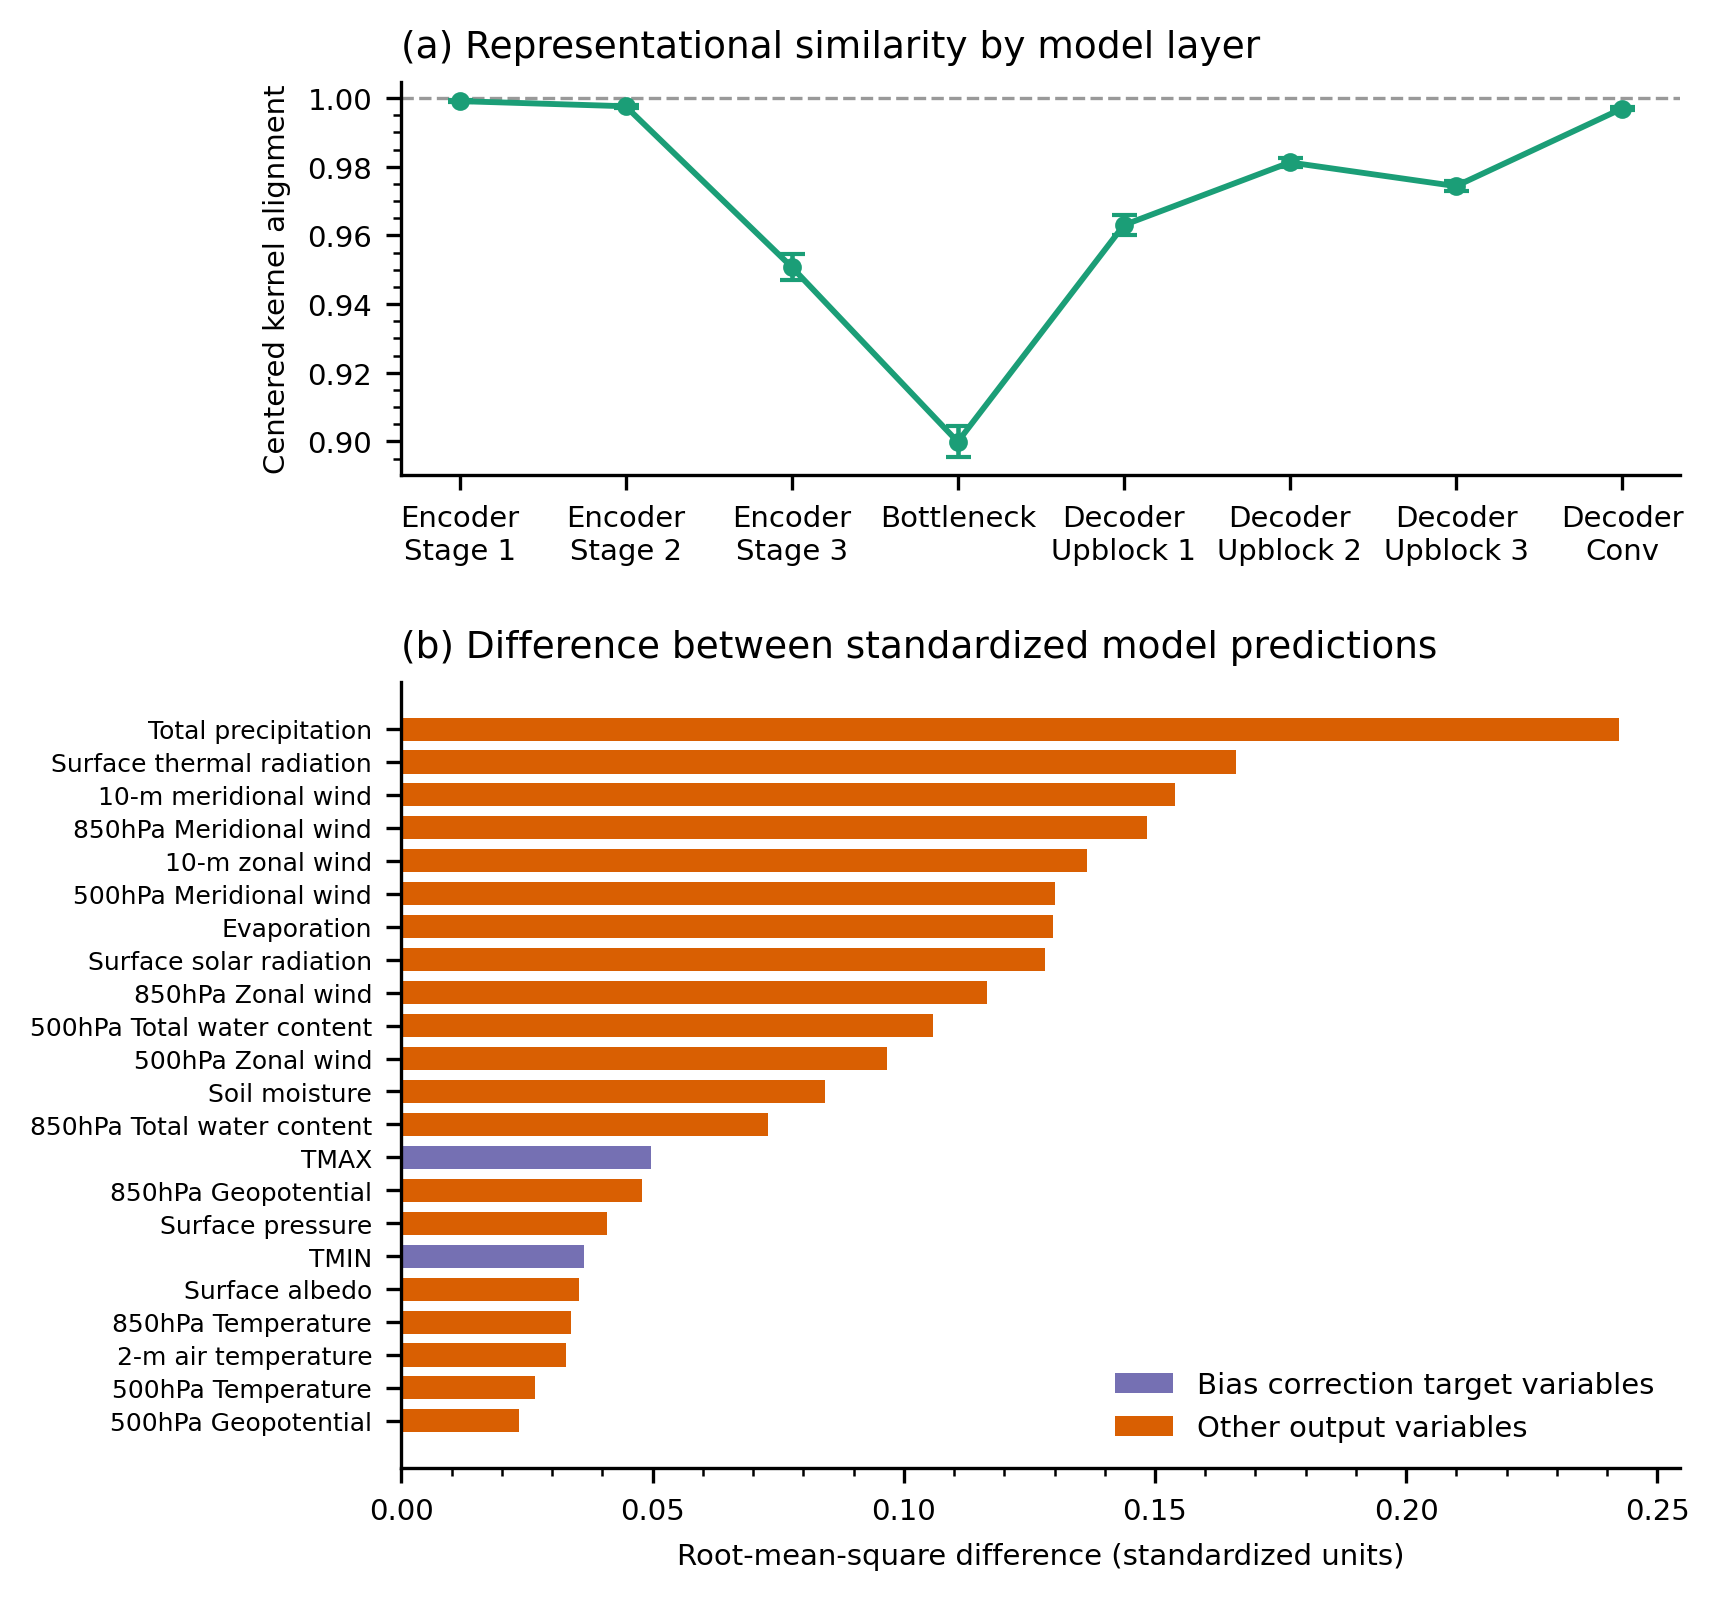

In [7]:
import matplotlib.ticker as mticker
from matplotlib.patches import Patch

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,   # embed fonts as editable text rather than curves -- most journals require this
    "ps.fonttype": 42,
})

COLOR_CKA = "#1b9e77"
COLOR_RMSE = "#d95f02"
COLOR_HEAT = "#7570b3"
BC_VARS = {"tmax", "tmin"}

STAGE_LABELS = {
    "layers.0": "Encoder\nStage 1", "layers.1": "Encoder\nStage 2",
    "layers.2": "Encoder\nStage 3", "layers.3": "Bottleneck",
    "up_block1": "Decoder\nUpblock 1", "up_block2": "Decoder\nUpblock 2",
    "up_block3": "Decoder\nUpblock 3", "up_block4": "Decoder\nConv",
}

# Plain-language names for the output variables, code kept in parentheses for readers who know
# the meteorological shorthand. Built from your config's variable lists (Section 1.2).
VAR_LABELS = {
    "t2m": "2-m air temperature", "tmax": "TMAX", "tmin": "TMIN",
    "sp": "Surface pressure", "u10": "10-m zonal wind", "v10": "10-m meridional wind",
    "sm": "Soil moisture", "alb": "Surface albedo",
    "SSR": "Surface solar radiation", "STR": "Surface thermal radiation",
    "TP": "Total precipitation", "EVAP": "Evaporation",
}
for var, lvl in [("Z", "Geopotential"), ("U", "Zonal wind"), ("V", "Meridional wind"), ("T", "Temperature"), ("Q_tot", "Total water content")]:
    for p in (500, 850):
        VAR_LABELS[f"{var}{p}"] = f"{p}hPa {lvl}"

# drop cube_embedding (NaN -- never executes in this config, see Section 8 discussion)
cka_plot_df = cka_df.dropna(subset=["cka_mean"]).reset_index(drop=True)
cka_plot_df["stage_label"] = cka_plot_df["block"].map(STAGE_LABELS)

# sort RMSE ascending so the largest value ends up at the top of the horizontal bar chart
out_plot_df = out_df.sort_values("rmse_og_vs_corr", ascending=True).reset_index(drop=True)
out_plot_df["var_label"] = out_plot_df["channel"].map(VAR_LABELS)
bar_colors = [COLOR_HEAT if v in BC_VARS else COLOR_RMSE for v in out_plot_df["channel"]]

fig = plt.figure(figsize=(5.5, 6.0), dpi=300)
gs = fig.add_gridspec(2, 1, height_ratios=[1, 2], hspace=0.35)

# ---- Panel (a): CKA by depth ----
ax0 = fig.add_subplot(gs[0])
ax0.errorbar(cka_plot_df["block"], cka_plot_df["cka_mean"], yerr=cka_plot_df["cka_std"],
             marker="o", markersize=3.5, color=COLOR_CKA, ecolor=COLOR_CKA,
             elinewidth=1.1, capsize=3, linewidth=1.4)
ax0.axhline(1.0, color="0.6", linestyle="--", linewidth=0.8, zorder=0)
ax0.set_ylabel("Centered kernel alignment", fontsize=7)
ax0.set_xticks(range(len(cka_plot_df)))
ax0.set_xticklabels(cka_plot_df["stage_label"])
ax0.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax0.tick_params(axis="both", direction="out", labelsize=7)
ax0.set_title("(a) Representational similarity by model layer", fontsize=9, loc="left")

# ---- Panel (b): RMSE by variable ----
ax1 = fig.add_subplot(gs[1])
ax1.barh(out_plot_df["var_label"], out_plot_df["rmse_og_vs_corr"], color=bar_colors, height=0.7)
ax1.set_xlabel("Root-mean-square difference (standardized units)", fontsize=7)
ax1.xaxis.set_minor_locator(mticker.AutoMinorLocator())
ax1.tick_params(axis="x", direction="out", labelsize=7)
ax1.tick_params(axis='y', direction="out", labelsize=6)
ax1.set_title("(b) Difference between standardized model predictions",
              fontsize=9, loc="left")

legend_handles = [Patch(facecolor=COLOR_HEAT, label="Bias correction target variables"),
                    Patch(facecolor=COLOR_RMSE, label="Other output variables")]
ax1.legend(handles=legend_handles, loc="lower right", frameon=False, fontsize=7)